# Soil depth to bedrock — raw vs STAC folder vs cloud

Checks that the soil depth raster is the same in the three places it lives:

1. **Raw**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\Soil_depth.tif`
2. **STAC folder**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_depth\cog\soil_depth.tif` (COG produced by `notebooks/26_soil_depth.ipynb`)
3. **Cloud**: the COG found through the public STAC catalog (`gca-stac-7`, collection `soil_depth`)

The raster is 172800 x 67200 pixels (46 GB uncompressed), so it is **never read as a whole**: a coarse preview is plotted, and the values are compared at full resolution on a few windows, read over HTTP range requests from the cloud COG.

Environment: `environment_exploration.yml` (Miniforge).

In [1]:
import io
import time
from pathlib import Path
from posixpath import join as urljoin

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac_client
import rasterio
import requests
import urllib3
from rasterio.windows import Window

## 1) Locations

In [2]:
data_vivian = Path(r"P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian")
raw_path = data_vivian / "Soil_depth.tif"
stac_folder_path = data_vivian / "stac" / "soil_depth" / "cog" / "soil_depth.tif"

gcs_protocol = "https://storage.googleapis.com"
catalog_url = urljoin(gcs_protocol, "gca-data-public", "gca", "gca-stac-7", "catalog.json")
collection_id = "soil_depth"
item_id = "soil_depth"

for p in (raw_path, stac_folder_path):
    print(p.is_file(), p)

True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\Soil_depth.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_depth\cog\soil_depth.tif


## 2) Find the data through the STAC catalog

In [3]:
# public objects are cached for 1 h: a query string forces a fresh copy of catalog.json
catalog = pystac_client.Client.open(f"{catalog_url}?nocache={time.time()}")
# get_collection() can return another collection on a static catalog: match the id explicitly
collection = next((c for c in catalog.get_children() if c.id == collection_id), None)
if collection is None:
    raise LookupError(f"Collection {collection_id} not found in {catalog_url}")

items = {i.id: i for i in collection.get_items()}
print("Collection:", collection.id, "|", collection.title)
print("Items:", list(items))

item = items[item_id]
cloud_href = item.assets["data"].href
assert collection_id in cloud_href, f"Unexpected href: {cloud_href}"
print("data asset:", cloud_href)
print("raster bands:", item.assets["data"].extra_fields.get("raster:bands"))

sources = {"raw (P:)": str(raw_path), "stac folder (P:)": str(stac_folder_path), "cloud (catalog)": cloud_href}

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\client.py:191: NoConformsTo: Server does not advertise any conformance classes.
  warnings.warn(NoConformsTo())


Collection: soil_depth | SOILDGRIDS Absolute Depth to Bedrock
Items: ['soil_depth']
data asset: https://storage.googleapis.com/gca-data-public/gca/soil_depth/soil_depth.tif
raster bands: [{'nodata': -32768, 'data_type': 'int32', 'spatial_resolution': 0.0020833, 'unit': 'cm'}]


c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


## 3) Compare the metadata of the three files

In [4]:
profiles = {}
for label, path in sources.items():
    with rasterio.open(path) as src:
        profiles[label] = {
            "shape": src.shape,
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "crs": src.crs.to_string(),
            "transform": tuple(round(v, 9) for v in src.transform)[:6],
            "tiled (COG)": src.is_tiled,
            "overviews": src.overviews(1),
            "compression": str(src.compression),
        }
pd.DataFrame(profiles).T

,shape,dtype,nodata,crs,transform,tiled (COG),overviews,compression
raw (P:),"(67200, 172800)",int32,-32768.0,EPSG:4326,"(0.002083333, 0.0, -180.0, 0.0, -0.002083333, ...",False,"[2, 4, 8, 16, 32, 64, 128]",Compression.deflate
stac folder (P:),"(67200, 172800)",int32,-32768.0,EPSG:4326,"(0.002083333, 0.0, -180.0, 0.0, -0.002083333, ...",True,"[2, 4, 8, 16, 32, 64, 128]",Compression.deflate
cloud (catalog),"(67200, 172800)",int32,-32768.0,EPSG:4326,"(0.002083333, 0.0, -180.0, 0.0, -0.002083333, ...",True,"[2, 4, 8, 16, 32, 64, 128]",Compression.deflate


## 4) Compare the values at full resolution on a few windows

Nile delta, Mekong delta, Netherlands and Himalaya (about 1920 x 1920 pixels each). The cloud file is read with HTTP range requests, only the needed tiles are downloaded.

In [5]:
WINDOWS = {  # lon0, lon1, lat0, lat1
    "nile_delta": (29.0, 33.0, 29.0, 32.0),
    "mekong_delta": (104.0, 108.0, 8.0, 12.0),
    "netherlands": (3.0, 7.0, 50.0, 54.0),
    "himalaya": (85.0, 89.0, 26.0, 30.0),
}

windows = {}
with rasterio.open(raw_path) as ref:
    for name, (lon0, lon1, lat0, lat1) in WINDOWS.items():
        row0, col0 = ref.index(lon0, lat1)
        row1, col1 = ref.index(lon1, lat0)
        windows[name] = Window(col0, row0, col1 - col0, row1 - row0)

data = {}
for label, path in sources.items():
    with rasterio.open(path) as src:
        for name, win in windows.items():
            data[(name, label)] = src.read(1, window=win)

labels = list(sources)
results = []
for name in windows:
    ref_arr = data[(name, labels[0])]
    for other in labels[1:]:
        arr = data[(name, other)]
        results.append({
            "window": name,
            "comparison": f"{labels[0]} vs {other}",
            "same shape": ref_arr.shape == arr.shape,
            "different pixels": int((ref_arr != arr).sum()) if ref_arr.shape == arr.shape else None,
            "valid pixels": int((ref_arr != profiles[labels[0]]["nodata"]).sum()),
            "identical": bool(ref_arr.shape == arr.shape and np.array_equal(ref_arr, arr)),
        })
display(pd.DataFrame(results))

if all(r["identical"] for r in results):
    print("OK: raw, stac folder and cloud contain exactly the same data in all windows.")
else:
    print("MISMATCH: see the table above.")

,window,comparison,same shape,different pixels,valid pixels,identical
0,nile_delta,raw (P:) vs stac folder (P:),True,0,2000349,True
1,nile_delta,raw (P:) vs cloud (catalog),True,0,2000349,True
2,mekong_delta,raw (P:) vs stac folder (P:),True,0,1928130,True
3,mekong_delta,raw (P:) vs cloud (catalog),True,0,1928130,True
4,netherlands,raw (P:) vs stac folder (P:),True,0,2332827,True
5,netherlands,raw (P:) vs cloud (catalog),True,0,2332827,True
6,himalaya,raw (P:) vs stac folder (P:),True,0,3456460,True
7,himalaya,raw (P:) vs cloud (catalog),True,0,3456460,True


OK: raw, stac folder and cloud contain exactly the same data in all windows.


## 5) Plot the windows

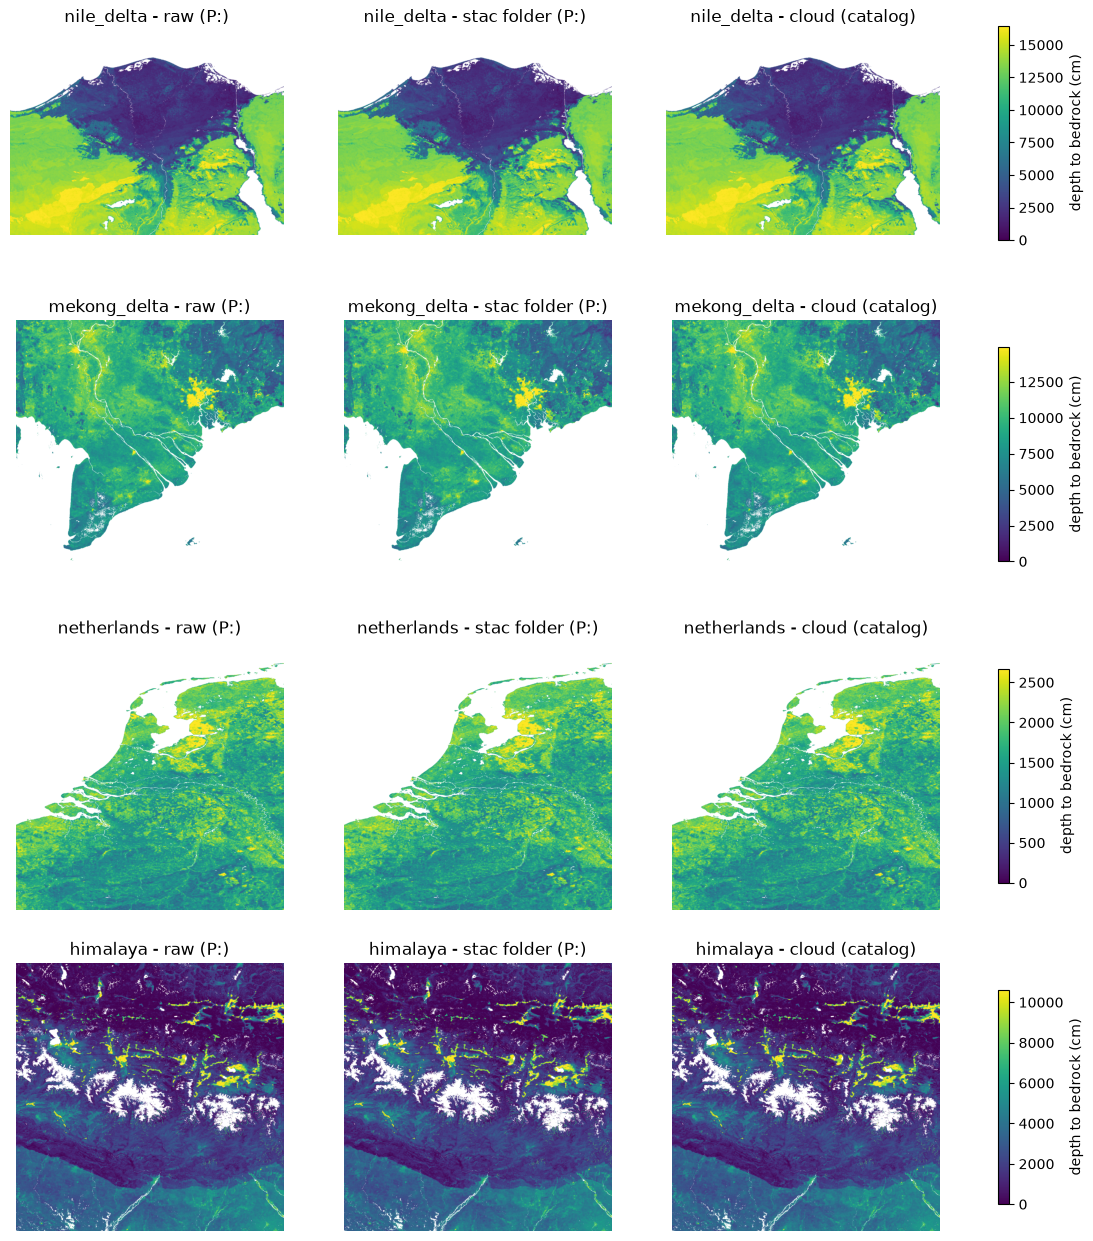

In [6]:
nodata = profiles[labels[0]]["nodata"]
fig, axes = plt.subplots(len(windows), len(labels), figsize=(5 * len(labels), 4 * len(windows)))
for r, name in enumerate(windows):
    vmax = max(np.percentile(a[a != nodata], 99) if (a != nodata).any() else 1 for k, a in data.items() if k[0] == name)
    for c, label in enumerate(labels):
        arr = np.ma.masked_equal(data[(name, label)], nodata)
        im = axes[r, c].imshow(arr, cmap="viridis", vmin=0, vmax=vmax)
        axes[r, c].set_title(f"{name} - {label}")
        axes[r, c].axis("off")
    fig.colorbar(im, ax=axes[r, :], label="depth to bedrock (cm)", shrink=0.8)
plt.show()

## 6) World preview from the overviews

Reading with a small `out_shape` makes GDAL use the overviews, so only a few MB are transferred, also from the cloud.

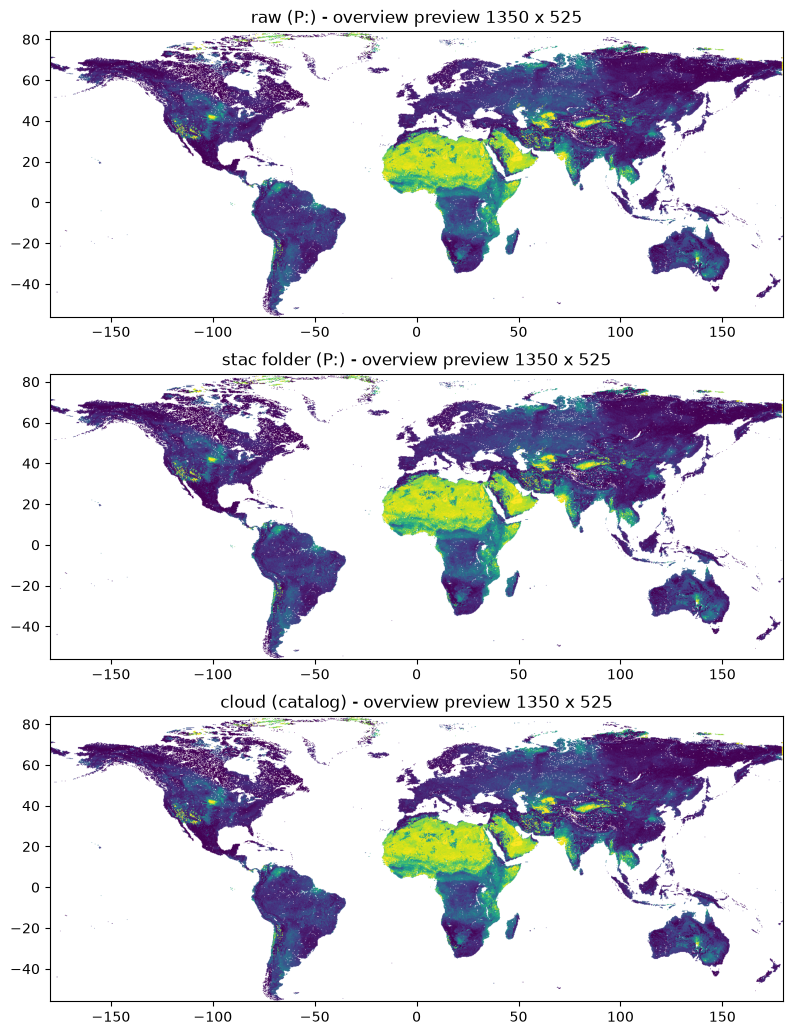

In [7]:
fig, axes = plt.subplots(len(labels), 1, figsize=(12, 4.2 * len(labels)))
for ax, (label, path) in zip(axes, sources.items()):
    with rasterio.open(path) as src:
        preview = src.read(1, out_shape=(src.height // 128, src.width // 128))
    ax.imshow(np.ma.masked_equal(preview, nodata), cmap="viridis", vmin=0, vmax=np.percentile(preview[preview != nodata], 99), extent=(-180, 180, -56, 84))
    ax.set_title(f"{label} - overview preview {preview.shape[1]} x {preview.shape[0]}")
plt.show()

## 7) Call the WMS service

Requests the layer published in GeoServer (step 8 of `scripts/26_soil_depth.ipynb`) through the `visual` asset of the STAC item. Needs access to the Deltares network. Colours come from the GeoServer style, so they differ from the plots above.

WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_depth | layer: soil_depth:soil_depth


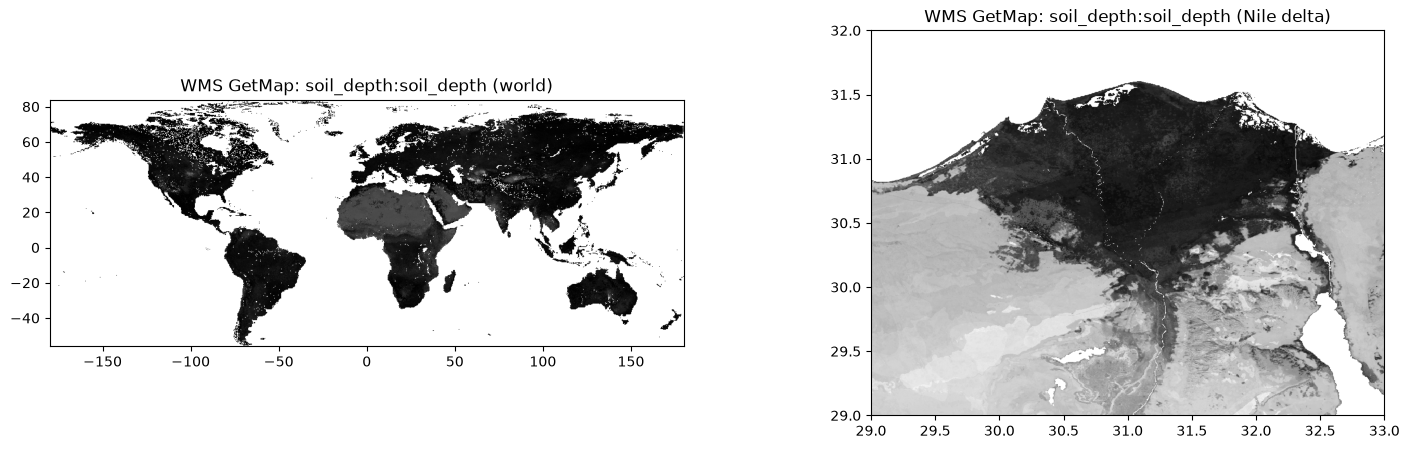

In [8]:
urllib3.disable_warnings()  # the internal GeoServer uses a self-signed certificate

wms_url = item.assets["visual"].href
layer = f"{collection_id}:{item_id}"  # workspace:layer as published in step 8
bbox = item.bbox
print("WMS asset:", wms_url, "| layer:", layer)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, (title, extent) in zip(axes, {"world": bbox, "Nile delta": [29.0, 29.0, 33.0, 32.0]}.items()):
    params = dict(
        SERVICE="WMS", VERSION="1.1.1", REQUEST="GetMap", LAYERS=layer, STYLES="",
        SRS="EPSG:4326", BBOX=",".join(str(v) for v in extent), WIDTH=1000, HEIGHT=int(1000 * (extent[3] - extent[1]) / (extent[2] - extent[0])),
        FORMAT="image/png", TRANSPARENT="true",
    )
    resp = requests.get(wms_url, params=params, verify=False, timeout=120)
    resp.raise_for_status()
    if not resp.headers.get("Content-Type", "").startswith("image"):
        raise RuntimeError(resp.text[:500])  # GeoServer returns XML on errors
    ax.imshow(mpimg.imread(io.BytesIO(resp.content), format="png"), extent=(extent[0], extent[2], extent[1], extent[3]))
    ax.set_title(f"WMS GetMap: {layer} ({title})")
plt.show()